# E77: With every matrix of Qwen3-1.7B masked, what still reaches the logits?

*2026-11-03, D1, `qwen-decomp-lead`. Record: `reports/analyses/2026-11-03_analysis_e77-open-points.md`. Independent check: `reports/reviews/2026-11-03_review_e77-masks-carry.md`.*

## The answer

With all 196 matrices masked by the original model's masks, Δ off, small changes in the stream barely reach the logits at early blocks. That holds even for changes the forward computes itself, against our lean. With another row's tokens under them, those masks keep the output within about 0.5 nats of the masks' own row. How much it still depends on its tokens is not measured. With fewer matrices masked more of the update passes, so the next run compares routings.


## What we were trying to test

The aim here is D1: a map on Qwen3-1.7B that keeps the decomposition faithful for a real update. A test that can fail a bad placement judges it. An earlier run, E74, found that masked reads barely respond to an update. In a masked forward each matrix's output is rebuilt from its subcomponents, each multiplied by a mask. With Δ off, the rebuilt output is the whole output. E74 added the whole fine-tuning update on top of this forward, and the logits hardly moved.

An independent check of E74 found no bug and left three points open. This job read them on saved updates, with no training and one cluster L40.

**Point one: is the loss about the update?** We scaled the masked sum at one block's seven matrices by a small factor. So the change is something the masked forward computes itself. The factor was set so this change moves the clean model as much as the update does at that block. If this change passes while the update does not, the loss is about the update. A broken hook would read as low as the update, with a cosine near zero.

**Point two: is masking all 196 at once the extreme case?** VPD's training masks a random subset at each position, a scheme its library calls routing. A routed-out matrix outputs its full weights. We masked 196, 147, 98, 49, 12 or 0 matrices, and also the library's own draw. Zero masked must read exactly as clean, which is the identity control.

**Point three: does the update move the forward under masks made on the fine-tuned model?** E72 had shown this forward gets no nearer the fine-tuned model. This read asks whether it moves at all.

The first read failed, so two reads were added. The **hook control** applies the same scaling at the last matrix alone, where only the final norm and the output head follow. The **swap** takes masks from one row and tokens from the next row, to see which clean output the result sits near.

**How to read the numbers.** Logit-shift amplitude is the masked logit shift's size over the clean one's, and 1 means as in the clean model. Transmission, written τ, is $\tau = \mathrm{KL}(\text{masked} \| \text{masked} + \text{change}) / \mathrm{KL}(W_0 \| W_0 + \text{change})$, and it also reads 1 for the clean model. It is quadratic, so 100 times in τ is about 10 times in amplitude.

**Masks and rows.** Fixed masks are W0's causal importance values $g$, Δ off. Stochastic masks are VPD's draw, $m = g + (1 - g)u$ with Δ's share $d$ uniform on 0 to 1. Every read uses the first 32 rows of 256 tokens. The updates are a first fine-tune at step 10, a gold-answer fine-tune at step 100, and a template fine-tune at step 100.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_open_points")
RES, FIG = ROOT / "results", ROOT / "figures"
E74 = Path("../experiments/qwen_transmission/results")

def load(path):
    return json.loads(Path(path).read_text())

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

SCORE, A1 = load(RES / "amend1_score.json"), load(RES / "amend1.json")
UPDATES = {"u1": "first fine-tune, step 10", "u2": "gold fine-tune, step 100", "u3": "template fine-tune, step 100"}


## What we expected, and why

**Own-output change: a medium lean that it passes, amplitude above 0.5 at blocks 0 and 7.** The change lies in what the masked forward already computes. E74's last-matrix control had read 0.75 to 1. Below the line on any cell stops the job.

**Fewer matrices masked: a medium lean that τ rises steeply.** We filed that τ with 49 masked would be over ten times τ with all masked, on each update and mask type. All four alike gives one label, and anything else is "mixed".

**Displacement: a medium lean that it is small.** The update's move under fine-tuned masks would be under 0.02 of the clean distance from W0 to the fine-tuned model.

**After the first read failed, three more.** The hook control was expected near 1. In the swap we leaned weakly towards "masks", meaning the output sits nearer the row that gave the masks. At later blocks we leaned that amplitude rises towards 1, as Gaussians had done in E74.

## What we observed

**The job stopped twice before it read everything.** The first run stopped at its filed rule when the own-output change failed. The second stopped at the hook control we added, whose cosine of 0.49 fell just under its line of 0.51. That control was badly specified, because its two terms read different streams, so we masked only the last matrix and reran. The rerun passed the line and read the rest.

### Does a change the masked forward computes itself reach the logits from early blocks?


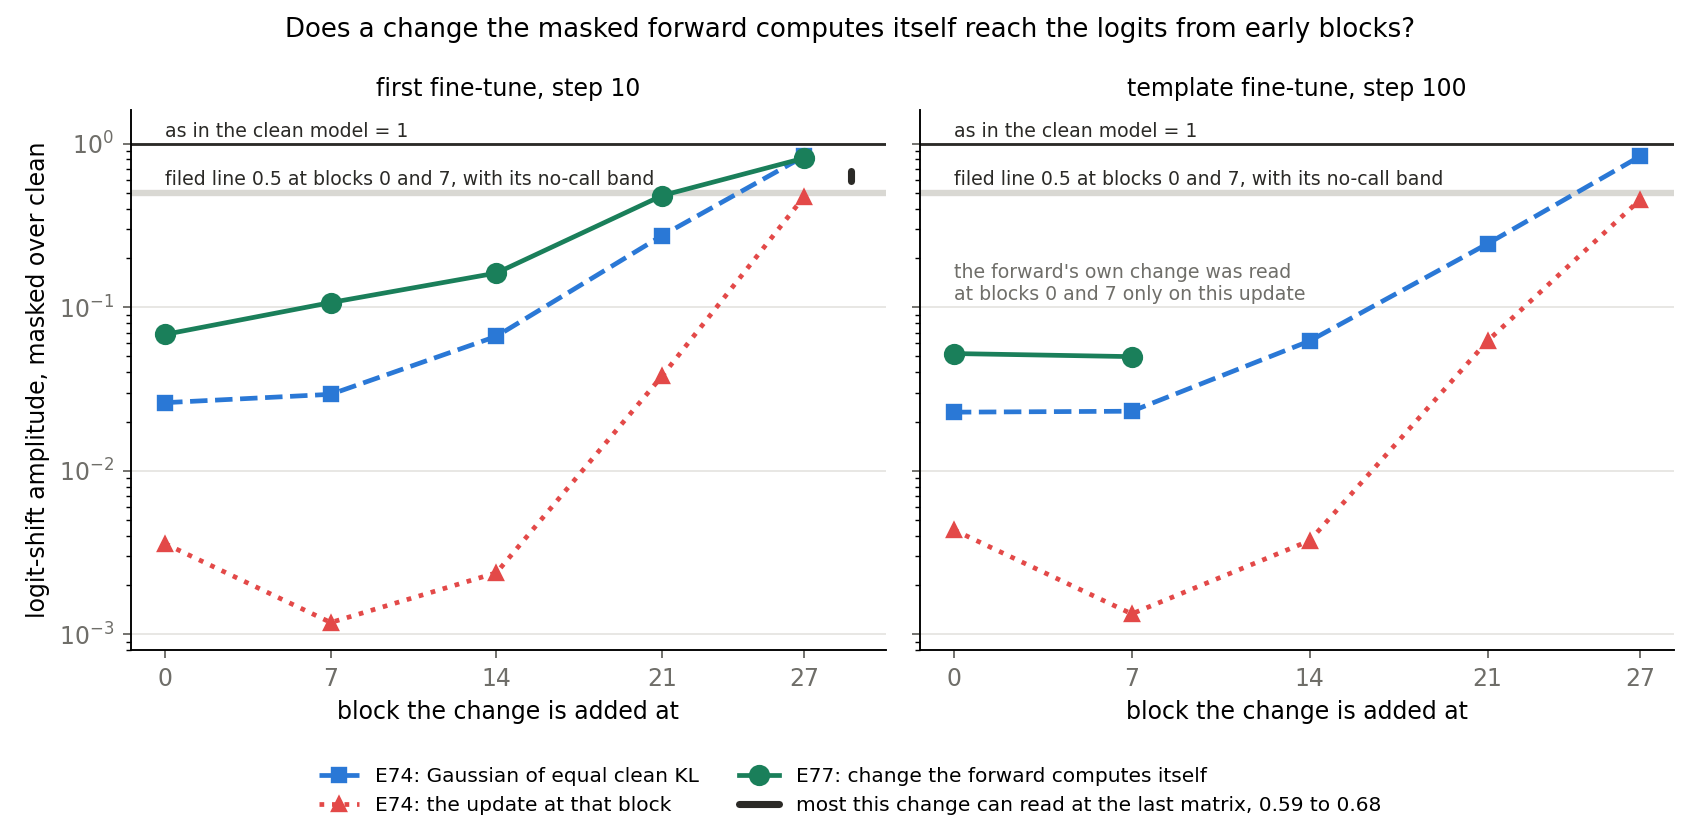

| update | block | amplitude | cosine | filed label |
|---|---|---|---|---|
| first fine-tune, step 10 | 0 | 0.068 | 0.050 | fails |
| first fine-tune, step 10 | 7 | 0.107 | 0.014 | fails |
| template fine-tune, step 100 | 0 | 0.052 | 0.046 | fails |
| template fine-tune, step 100 | 7 | 0.050 | 0.012 | fails |
| first fine-tune, step 10 | 14 | 0.162 | 0.061 | no rule |
| first fine-tune, step 10 | 21 | 0.481 | 0.182 | no rule |
| first fine-tune, step 10 | 27 | 0.815 | 0.619 | no rule |

In [2]:
show("own_by_block.png")
each = SCORE["own_output"]["each"]
rows = [[UPDATES[k[:2]], k[3:], f"{v['amp']:.3f}", f"{v['cos']:.3f}", v["label"]] for k, v in each.items()]
rows += [[UPDATES["u1"], b, f"{A1[f'own_{b}']['amp']:.3f}", f"{A1[f'own_{b}']['cos']:.3f}", "no rule"] for b in (14, 21, 27)]
table(["update", "block", "amplitude", "cosine", "filed label"], rows)


**Reading it.** No, and this reverses our lean. At blocks 0 and 7 the green points read 0.05 to 0.11, on both updates, against a line at 0.5. Their cosines with the clean shift are 0.01 to 0.05. The change does pass two to four times more than E74's Gaussian of equal clean KL. It passes 12 to 90 times more than the update.

On the first fine-tune amplitude rises with block, to 0.16, 0.48 and 0.81 at blocks 14, 21 and 27, as we leaned. Blocks 0, 7 and 14 read low. Block 21 sits just under the line that was filed for blocks 0 and 7, and it is not clearly deaf.

One caveat moves the bar without moving the verdict. The next figure shows this change cannot read 1 even at the last matrix, where the most it reads is 0.59 to 0.68. The early blocks of the first fine-tune still read five to ten times below that. Clean and masked terms also read different inputs, so a low cosine is not loss alone.

### Does the last-matrix control read near 1, as the plan expected?


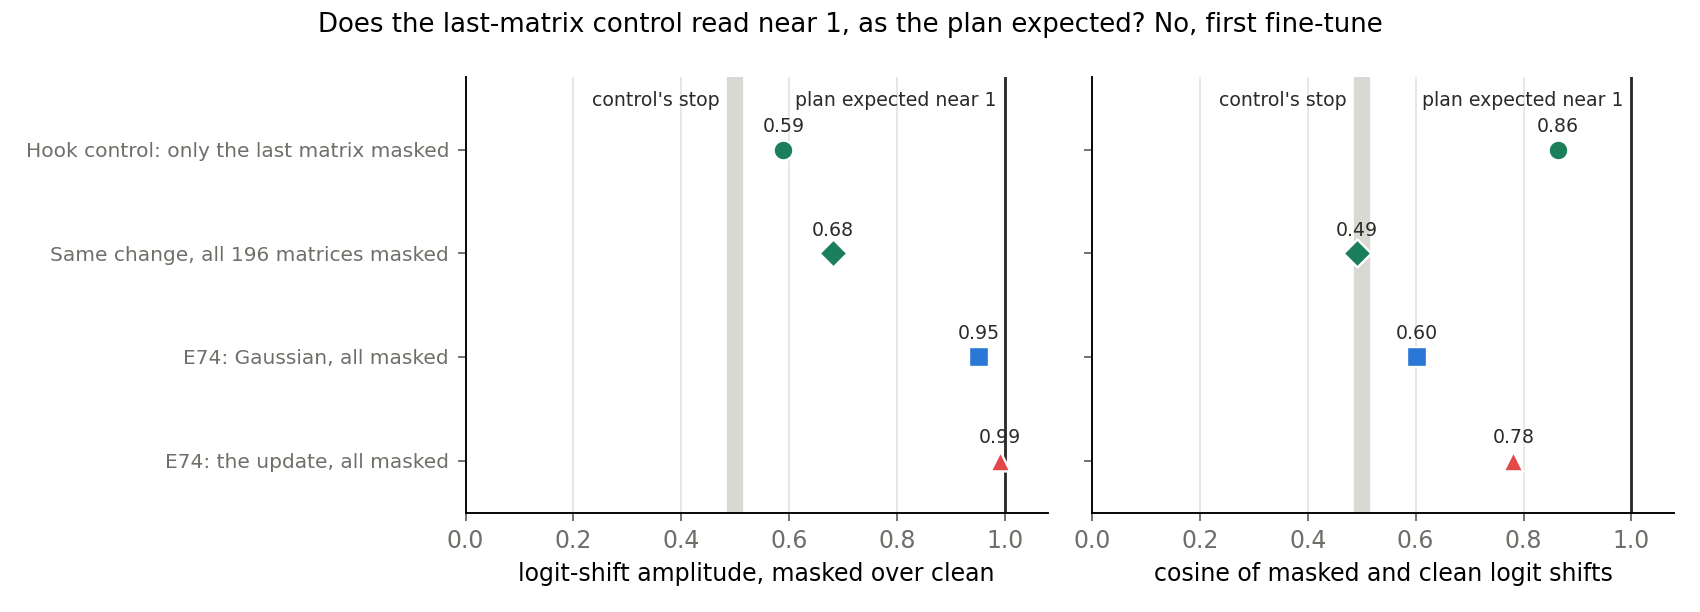

In [3]:
show("hook.png")


**Reading it.** No, and the expectation was wrong rather than the hook. With only the last matrix masked, the control read amplitude 0.59 and cosine 0.86, where we expected near 1. That cleared the filed line, so the job went on.

Reading the code shows only the final norm and the output head follow this matrix. The same vector is added in the clean pair and in the masked pair. So the two logit shifts differ only because the norm is read at two base points: the clean output and the masked output.

Two causes could shrink the masked shift: a larger base size, or more of the added vector lying along the base. Saved numbers do not say which. A test of about a minute is queued as stage 0 of E76, and it will also confirm the algebra.

The independent check found no bug in the hook. The identity control read exactly 1 and every all-masked read matched E74's. This gap does not touch the swap, the displacement or the controls of the routing read.

### Where does the output sit when masks come from one row and tokens from another?


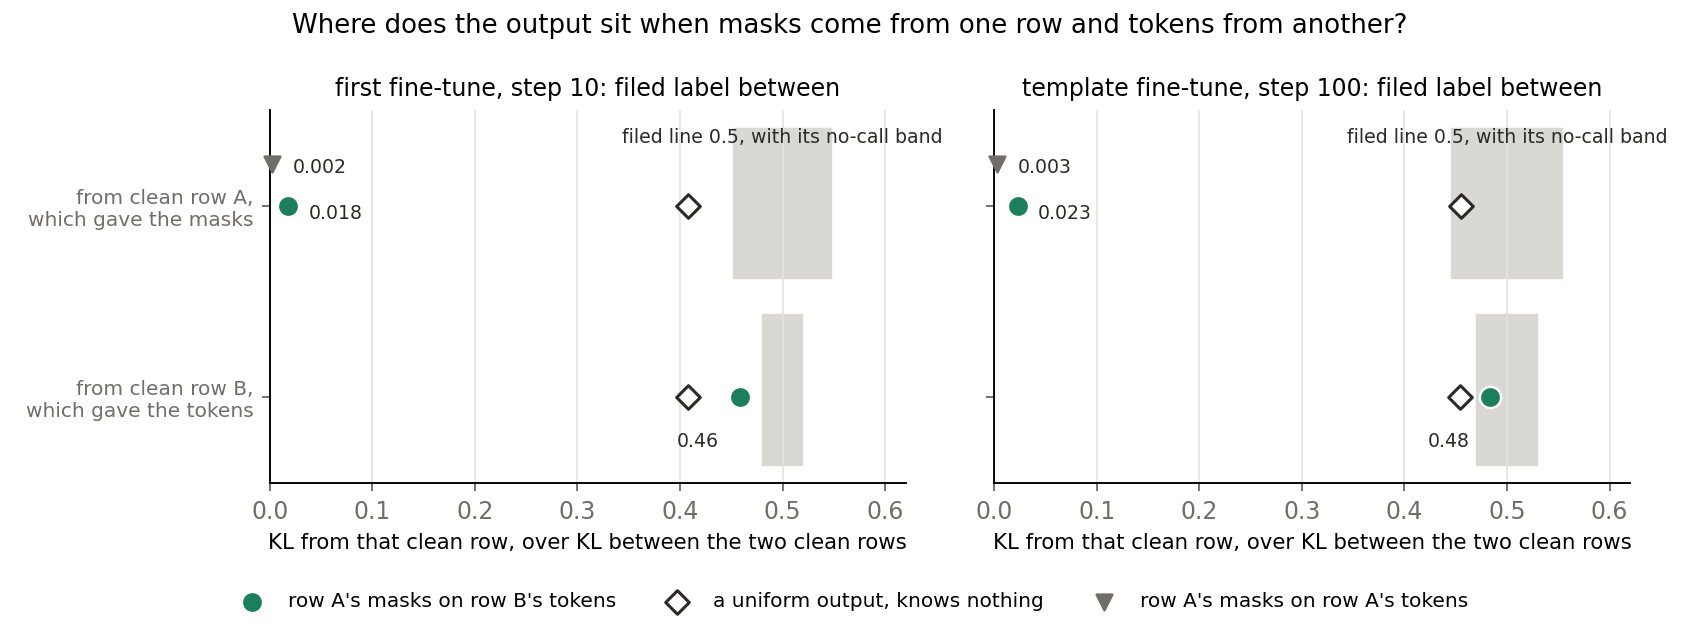

| update | own masks, own tokens | KL from clean row A | KL from clean row B | KL between clean rows |
|---|---|---|---|---|
| first fine-tune, step 10 | 0.067 | 0.508 | 12.74 | 27.84 |
| template fine-tune, step 100 | 0.069 | 0.565 | 12.01 | 24.76 |

In [4]:
show("swap.png")
rows = []
for u in ("u1", "u3"):
    r = load(RES / u / "amend1_swap.json")
    n = len(r["sums"]["K0"]) * r["T"]
    m = {k: sum(v) / n for k, v in r["sums"].items()}
    rows.append([UPDATES[u], f"{m['K0']:.3f}", f"{m['K_AL']:.3f}", f"{m['K_BL']:.2f}", f"{m['K_AB']:.2f}"])
table(["update", "own masks, own tokens", "KL from clean row A", "KL from clean row B", "KL between clean rows"], rows)


**Reading it.** The filed label is "between" on both updates, it stands, and our weak lean towards "masks" was not met. The output sits within about 0.5 nats of the row that gave the masks, where each row's own masks read about 0.07 nats. On that ruler it is 0.02 of the way from row A towards row B.

The second number on this figure cannot separate anything. It sits near 0.5 because of KL's tails. Two clean rows read 25 to 28 nats apart, more than twice the logarithm of the vocabulary. A uniform output that knows nothing reads 0.41 on this ruler for the first fine-tune and 0.45 for the template, as the diamonds show.

So the first number shows the masks hold enough of row A's likely tokens. The tokens still matter on average, since KL from row A rises about eight times once they change. These sums are means over positions, and a mixture of the two rows at about half of positions would fit them as well. How much the output depends on its tokens is not measured.

### How much of the whole update reaches the logits as fewer matrices are masked?


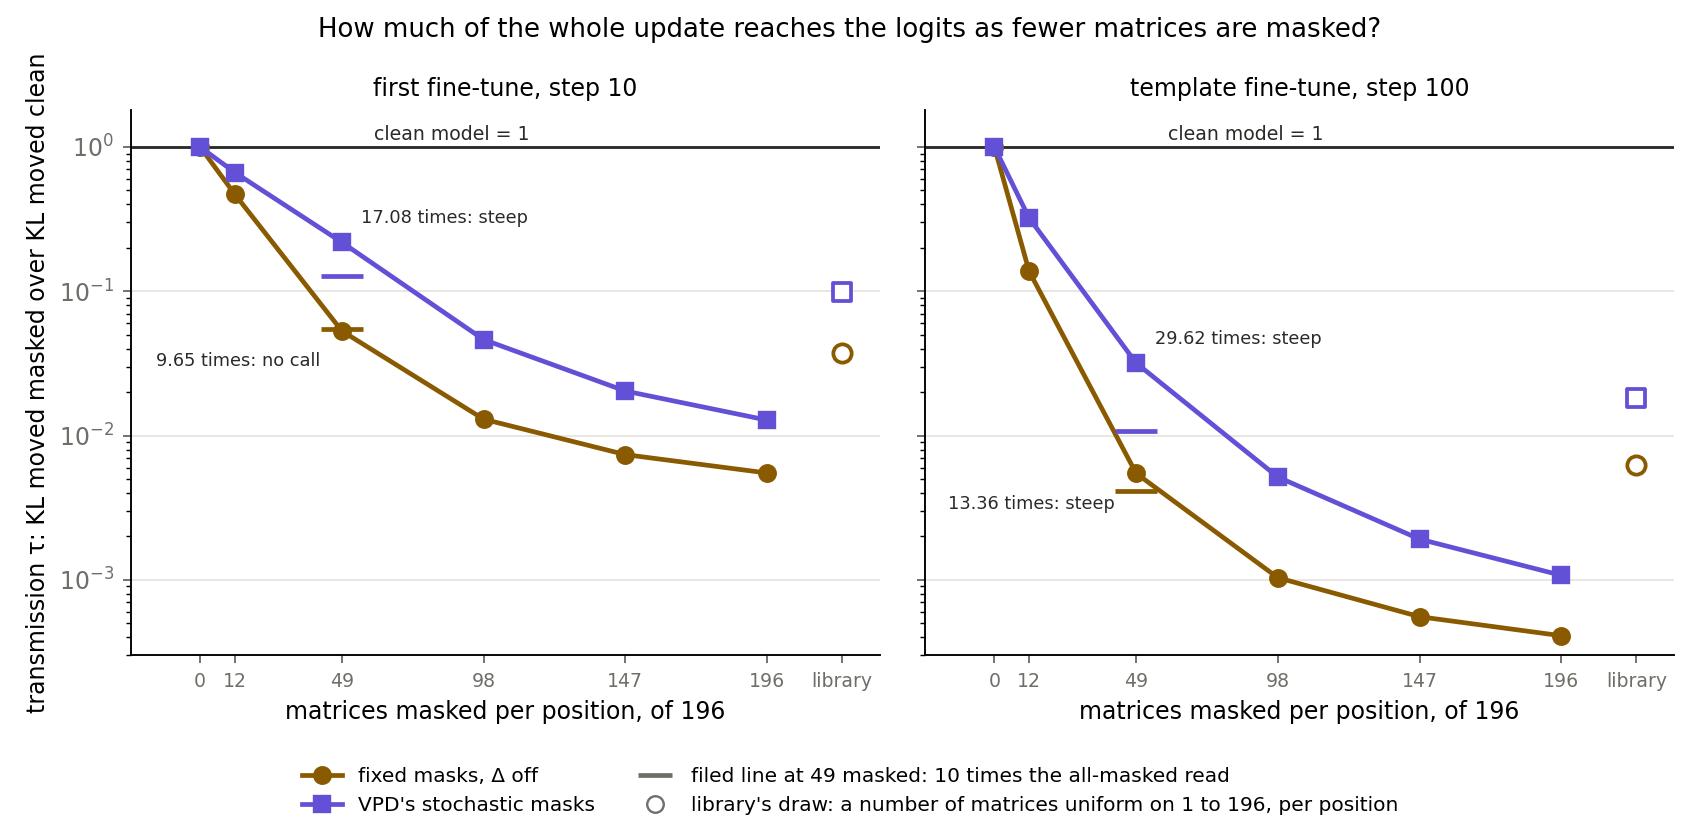

| update, masks | τ, 196 masked | τ, 49 masked | τ, 12 masked | ratio at 49, filed label |
|---|---|---|---|---|
| first fine-tune, step 10, fixed | 0.00550 | 0.0531 | 0.470 | 9.65, no call |
| first fine-tune, step 10, stochastic | 0.01279 | 0.2184 | 0.665 | 17.08, steep |
| template fine-tune, step 100, fixed | 0.00041 | 0.0055 | 0.138 | 13.36, steep |
| template fine-tune, step 100, stochastic | 0.00107 | 0.0318 | 0.322 | 29.62, steep |

In [5]:
show("routing.png")
rows = []
for key, r in SCORE["routing"]["each"].items():
    p = r["points"]
    rows.append([f"{UPDATES[key[:2]]}, {key[3:]}", f"{p['k196']['tau']:.5f}", f"{p['k49']['tau']:.4f}", f"{p['k12']['tau']:.3f}", f"{r['ratio']:.2f}, {r['label']}"])
table(["update, masks", "τ, 196 masked", "τ, 49 masked", "τ, 12 masked", "ratio at 49, filed label"], rows)


**Reading it.** Masking all 196 is the extreme case, and the filed overall label is "mixed". Three of the four ratios read steep, at 17.08, 13.36 and 29.62. The first fine-tune under fixed masks read 9.65, inside the no-call band of 8.89 to 11.11. So the lean held on three cells and the fourth gets no call.

With only 12 matrices masked, τ reads 0.14 to 0.67, where all-masked reads 0.0004 to 0.013. The routed-out matrices read the full weights, and the update then gets through. The library's draw reads 0.006 to 0.10, near the read with 49 masked or between 49 and 98.

Because τ is quadratic, the amplitude gain from 196 to 49 masked is only two to 3.5 times. In this read the update enters in full at every matrix, where the library's own Δ would pass only a share of it at a routed-out matrix. The routes are uniform, so this says nothing about which matrices matter.

### How far does the update move the forward under masks made on the fine-tuned model?


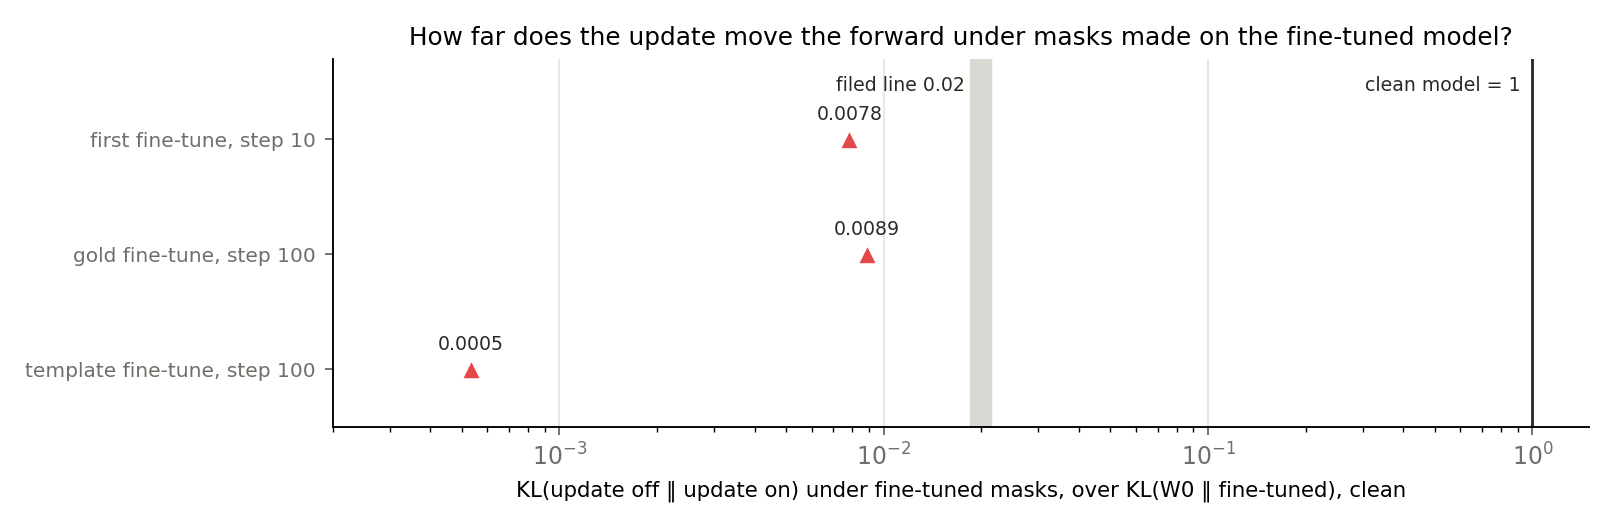

In [6]:
show("displacement.png")


**Reading it.** Very little, as we leaned. The move reads 0.008 of the clean distance on the first fine-tune, 0.009 on the gold fine-tune and 0.0005 on the template, against a filed line of 0.02. The clean model reads 1 on this ruler and no update reads 0. So under these masks the update barely moves the forward at all, which goes further than E72's reading that it gets no nearer. The measure is blind to direction, and masks made on the fine-tuned model may already hold part of what the update would add.

## What we learned

With all matrices masked, early blocks respond weakly to small changes of several kinds, not only to the update. So part of E74's finding is about this forward's response. The update itself still passes far less than either other change. "All 196 masked" must be stated with any such reading, because with 12 masked more than a tenth of the update's KL passes on every cell.

This bears on the map D1 chose, teacher training with masks in its loss. A masked loss term with all matrices masked can hardly teach early blocks, because a change there barely reaches the term. With matrices routed out, those matrices carry the update around the masks, so the term can fall with the masks doing no work. That is an inference from forward reads, since no gradient was read here, and it is why E76's plan compares routings.

The fine-tuned masks' reading also grows firmer: the update barely moves that forward at all. Masked tests still cannot pass a placement, so D1 keeps resting on the clean-model table.

## How compelling is the evidence

Every read is a mean over 32 rows of 256 tokens, on two updates, or three for displacement. The later blocks and the hook control were read on the first fine-tune alone. Row-to-row noise is small: the jackknife relative error reads 0.013 on amplitude and 0.039 on τ, and the no-call bands use twice that.

The controls held. Zero masked read exactly 1, and all-masked reproduced E74's numbers to every printed digit. The independent check recomputed the labels by hand from the per-row sums and found no bug. It could not rerun anything on a GPU.

The own-output read used fixed masks only, one sign and one size of change. It is therefore silent on stochastic masks, which E76 would train under. Row pairing was run once, though the check found no pair sharing a prefix.

## Surprises

**Something unexpected happened that I cannot explain.** We filed a medium lean that a change the masked forward computes itself would pass at early blocks, with amplitude above 0.5. It read 0.05 to 0.11 on all four cells, with cosines near zero.

The hook control missed its expected value of near 1. The cause is narrowed to the final norm, read at two base points, and not yet told apart.

The weak lean on the swap read "between", not "masks", and it stands as filed.

Not asked, but worth a line: KL from clean does not fall as fewer matrices are masked. On the first fine-tune under fixed masks, its sum reads 550 with all masked and 1156 with 12 masked. This fits a forward that works as one network, and also a library trained mostly all-masked.

**A correction.** The lead told the user in chat, at 18:05 and about 19:40, a provisional reading that the masks carry the output. The independent check narrowed it to the statement above.

## What next

1. **The final-norm test, stage 0 of E76, about a minute.** If rebuilt shifts miss 0.59 and 0.86, something besides the norm is involved. The hook is then suspect and that job stops.
2. **E76's comparison of a clean term alone, all-masked and the library's routing.** All-masked may teach only late blocks, and routing may lower the term without masks working. Then neither is plainly the map the user meant, and it goes back to the user.
3. **A swap with its missing reference and a small token change, under a new code.** KL from row B of the row's own-masks forward would say whether row B's tokens add anything. E77 has used both amendments.

## Scorecard


In [7]:
sw = {u: A1[f"swap_{u}"] for u in ("u1", "u3")}
table(["id", "claim", "rule", "read", "verdict"], [
    ["own_output", "own change passes at blocks 0, 7", "amplitude above 0.5, band 0.487-0.513", "0.05-0.11", "fails; lean reversed"],
    ["routing_steepness", "τ rises over tenfold by 49 masked", "ratio above 10, band 8.89-11.11", "9.65, 17.08, 13.36, 29.62", "mixed: no call, steep, steep, steep"],
    ["displacement", "update's move is small", "share below 0.02", "0.0078, 0.0089, 0.0005", "small; lean held"],
    ["swap", "output nearer the masks' row", "follow_A below and follow_B above 0.5", f"A {sw['u1']['follow_A']:.3f}, {sw['u3']['follow_A']:.3f}; B {sw['u1']['follow_B']:.3f}, {sw['u3']['follow_B']:.3f}", "between; stands; weak lean masks"],
    ["later_blocks", "amplitude rises with block", "no threshold", "0.16, 0.48, 0.81", "as leaned"],
    ["hook, Amendment 1", "control on the masked stream", "amplitude, cosine above 0.513", "0.68, 0.49", "stop; control mis-specified"],
    ["hook, Amendment 2", "control on the clean stream", "same line; expected near 1", "0.59, 0.86", "passed line; missed expected value"],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| own_output | own change passes at blocks 0, 7 | amplitude above 0.5, band 0.487-0.513 | 0.05-0.11 | fails; lean reversed |
| routing_steepness | τ rises over tenfold by 49 masked | ratio above 10, band 8.89-11.11 | 9.65, 17.08, 13.36, 29.62 | mixed: no call, steep, steep, steep |
| displacement | update's move is small | share below 0.02 | 0.0078, 0.0089, 0.0005 | small; lean held |
| swap | output nearer the masks' row | follow_A below and follow_B above 0.5 | A 0.018, 0.023; B 0.458, 0.483 | between; stands; weak lean masks |
| later_blocks | amplitude rises with block | no threshold | 0.16, 0.48, 0.81 | as leaned |
| hook, Amendment 1 | control on the masked stream | amplitude, cosine above 0.513 | 0.68, 0.49 | stop; control mis-specified |
| hook, Amendment 2 | control on the clean stream | same line; expected near 1 | 0.59, 0.86 | passed line; missed expected value |

## Departures from the literature

Against the library's routing, `param-decomp` at commit 177d0cce8.

- The library runs 90% of documents all-routed under persistent adversarial sources and only 10% under this routing, with fresh uniform sources. Here the library's draw is that 10%, with no adversary, because adversarial sources were not part of the question.
- The update enters in full at every matrix, as in E74, where the library's Δ would pass a share of it at a routed-out matrix. We keep E74's read for comparison.
- One mask draw per row across route draws, as in E74, where the library draws afresh.
- Fixed numbers of masked matrices and fixed masks are ours, to read a curve.
- 32-bit floats and torch's generators, where the library uses JAX's generators.

## Not run

1. The final-norm test, queued in E76's stage 0.
2. The swap's missing reference: KL from row B of the own-masks forward on row A's tokens, and top-token agreement per position.
3. A small input change under fixed masks, a single token, read against the clean model's response. That is the read that would say how much the forward depends on its tokens.
4. Other row pairings and other mask sources.
5. The own-output change under stochastic masks, of the other sign, and at later blocks on the template.
6. Adversarial sources; the library's own Δ share on the update; the own-output and routing reads on the gold fine-tune.
7. Accuracy, and any gradient of a masked loss.

## Provenance

Results in `experiments/qwen_open_points/results/`: `amend1_score.json`, `amend1.json`, `score.json`, `run.log`, `u1/`, `u2/`, `u3/`. Jobs 50608, 50613 and 50616 on one cluster L40, `normal` QoS, $0, about 96 minutes for the last. Plan `reports/plans/2026-11-03_plan_e77-open-points.md`, with Amendments 1 and 2; both amendments are used.
